## paso 1 validar columnas

In [1]:
import pandas as pd
from pathlib import Path

archivos_2026 = sorted(Path("datos/2026").glob("datos_abiertos_2026_*.csv"))
print(f"Archivos encontrados: {len(archivos_2026)}")

for ruta in archivos_2026:
    df = pd.read_csv(ruta, encoding="latin-1", dtype=str)
    print(f"\n=== {ruta.name} | {len(df):,} filas | {len(df.columns)} columnas")
    print("Columnas:", list(df.columns))
    print(df.head(2).to_string())

Archivos encontrados: 5

=== datos_abiertos_2026_01.csv | 357,180 filas | 8 columnas
Columnas: ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
   Viaje_Id Usuario_Id Genero Año_de_nacimiento     Inicio_del_viaje        Fin_del_viaje Origen_Id Destino_Id
0  42349943    1726166      M              1967  2026-01-01 00:03:07  2026-01-01 00:03:39        64         64
1  42349944    1726166      M              1967  2026-01-01 00:04:05  2026-01-01 00:13:20        64         35

=== datos_abiertos_2026_02.csv | 333,756 filas | 8 columnas
Columnas: ['Viaje_Id', 'Usuario_Id', 'Genero', 'AÃ±o_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
   Viaje_Id Usuario_Id Genero AÃ±o_de_nacimiento     Inicio_del_viaje        Fin_del_viaje Origen_Id Destino_Id
0  42755487     530602      M               1995  2026-02-01 00:00:01  2026-02-01 00:10:58        50         13
1  42755488      71721      M   

## Paso 2 Carga y limpieza de 2026

In [2]:
import numpy as np
import holidays

PROCESADO = Path("procesado")
seleccion = pd.read_csv(PROCESADO / "estaciones_seleccionadas.csv")
estaciones = seleccion["origen"].tolist()

def convertir_fecha(serie):
    fecha = pd.to_datetime(serie, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    corto = fecha.isna()
    fecha.loc[corto] = pd.to_datetime(serie[corto], format="%d/%m/%Y %H:%M", errors="coerce")
    return fecha

partes = []
for ruta in archivos_2026:
    df = pd.read_csv(ruta, encoding="latin-1", usecols=[4, 5, 6, 7], dtype=str)
    df.columns = ["inicio", "fin", "origen", "destino"]
    df["inicio"] = convertir_fecha(df["inicio"])
    df["fin"] = convertir_fecha(df["fin"])
    mes = int(ruta.stem.split("_")[-1])
    print(f"{ruta.name}: {len(df):,} filas | fechas no convertidas: {df['inicio'].isna().sum()} "
          f"| fuera del mes: {(df['inicio'].dt.month != mes).sum()}")
    partes.append(df)

v26 = pd.concat(partes, ignore_index=True)
del partes
v26["origen"] = v26["origen"].astype(int)
v26["duracion_min"] = (v26["fin"] - v26["inicio"]).dt.total_seconds() / 60

n0 = len(v26)
v26 = v26[(v26["duracion_min"] >= 1) & (v26["duracion_min"] <= 1440)]
print(f"\nViajes 2026: {n0:,} | después de la limpieza: {len(v26):,} ({1 - len(v26) / n0:.2%} eliminados)")

datos_abiertos_2026_01.csv: 357,180 filas | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2026_02.csv: 333,756 filas | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2026_03.csv: 376,243 filas | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2026_04.csv: 351,851 filas | fechas no convertidas: 0 | fuera del mes: 0
datos_abiertos_2026_05.csv: 315,895 filas | fechas no convertidas: 0 | fuera del mes: 0

Viajes 2026: 1,734,925 | después de la limpieza: 1,677,352 (3.32% eliminados)


## Paso 3 Tabla estacion-hora de 2026, con ceros y variables

In [3]:
v = v26[v26["origen"].isin(estaciones)].copy()
v["hora_inicio"] = v["inicio"].dt.floor("h")
conteo = v.groupby(["origen", "hora_inicio"]).size().rename("salidas")

horas = pd.date_range("2026-01-01 00:00", "2026-05-31 23:00", freq="h")
indice = pd.MultiIndex.from_product([estaciones, horas], names=["origen", "hora_inicio"])
t26 = conteo.reindex(indice, fill_value=0).reset_index()

fuera = t26["hora_inicio"].dt.hour.between(1, 4)
print(f"Salidas entre 1:00 y 4:59: {t26.loc[fuera, 'salidas'].sum():,}")
t26 = t26.loc[~fuera].reset_index(drop=True)

f = t26["hora_inicio"]
t26["anio"] = f.dt.year
t26["mes"] = f.dt.month
t26["dia_semana"] = f.dt.dayofweek
t26["hora"] = f.dt.hour
t26["fin_de_semana"] = (t26["dia_semana"] >= 5).astype(int)
festivos_2026 = holidays.Mexico(years=[2026])
t26["festivo"] = f.dt.normalize().isin(pd.to_datetime(list(festivos_2026.keys()))).astype(int)
t26 = t26.merge(seleccion[["origen", "latitude", "longitude", "dpcapacity"]], on="origen", how="left")

print(f"Filas: {len(t26):,}  (esperado: 30 x 151 días x 20 horas = {30 * 151 * 20:,})")
print(f"Horas con cero salidas: {(t26['salidas'] == 0).mean():.1%}")
print("Festivos de enero a mayo de 2026:",
      [f"{d} {n}" for d, n in sorted(festivos_2026.items()) if d.month <= 5])

# ¿Alguna de las 30 estaciones dejó de operar en algún mes?
por_mes = v.groupby(["origen", v["inicio"].dt.month]).size().unstack(fill_value=0)
sin_viajes = por_mes[(por_mes == 0).any(axis=1)]
print(f"Estaciones con algún mes sin salidas: {len(sin_viajes)}")
if len(sin_viajes):
    print(sin_viajes.to_string())

# Comparación del nivel de demanda entre periodos
tabla = pd.read_parquet(PROCESADO / "tabla_modelo.parquet")
print("\nSalidas promedio por estación-hora:")
print(f"  2024: {tabla.loc[tabla['anio'] == 2024, 'salidas'].mean():.2f}")
print(f"  2025: {tabla.loc[tabla['anio'] == 2025, 'salidas'].mean():.2f}")
print(f"  2026 (ene-may): {t26['salidas'].mean():.2f}")
print(f"  2025 (ene-may): {tabla.loc[(tabla['anio'] == 2025) & (tabla['mes'] <= 5), 'salidas'].mean():.2f}")

t26.to_parquet(PROCESADO / "tabla_2026.parquet", index=False)

Salidas entre 1:00 y 4:59: 6
Filas: 90,600  (esperado: 30 x 151 días x 20 horas = 90,600)
Horas con cero salidas: 18.8%
Festivos de enero a mayo de 2026: ['2026-01-01 Año Nuevo', '2026-02-02 Día de la Constitución', '2026-03-16 Natalicio de Benito Juárez', '2026-05-01 Día del Trabajo']
Estaciones con algún mes sin salidas: 6
inicio     1     2     3     4  5
origen                           
50      4482  4208  5198  4631  0
52      4746  4231  4958  4489  0
54      4067  3849  4397  3252  0
58      2777  2570  2914  2583  0
66      2172  1835  2081  1970  0
260     3513  3154  3561  3586  0

Salidas promedio por estación-hora:
  2024: 5.42
  2025: 5.29
  2026 (ene-may): 4.81
  2025 (ene-may): 5.40


## Paso 4 verificar el porcentaje de las 30 estacioens

In [4]:
limpios = pd.read_parquet(PROCESADO / "viajes_limpios.parquet", columns=["inicio", "origen"])
es_2024 = limpios["inicio"].dt.year == 2024
de_las_30 = limpios.loc[es_2024, "origen"].isin(estaciones)
print(f"Las 30 estaciones concentran el {de_las_30.mean():.2%} de las salidas de 2024 "
      f"({de_las_30.sum():,} de {es_2024.sum():,})")
del limpios

Las 30 estaciones concentran el 26.45% de las salidas de 2024 (1,190,898 de 4,502,029)


## Paso 5

In [5]:
cerradas = sin_viajes.index.tolist()
nombres = seleccion.set_index("origen")["name"]

print("Última salida registrada en 2026:")
for est in cerradas:
    print(f"  {est:>4}  {nombres[est]:<50} {v.loc[v['origen'] == est, 'inicio'].max()}")

print("\nSalidas diarias de esas 6 estaciones, del 20 al 30 de abril:")
diario = (v[v["origen"].isin(cerradas)]
          .groupby([v["inicio"].dt.normalize(), "origen"]).size().unstack(fill_value=0))
print(diario.loc["2026-04-20":"2026-04-30"].to_string())

print("\nSalidas por mes de las otras 24 estaciones:")
otras = por_mes.drop(index=cerradas)
print(otras.sum().to_string())

Última salida registrada en 2026:
    50  (GDL-048) C. Constancio Hernández/ Av. Juaréz      2026-04-30 23:44:31
    52  (GDL-050) C.Pedro Moreno /Federalismo              2026-04-30 23:41:59
    54  (GDL-052) Av. Juarez /16 de Septiembre             2026-04-30 23:52:19
    58  (GDL-056) Av. 16 de Sept. / C. Miguel Blanco       2026-04-30 23:43:57
    66  (GDL-064) C. Marsella / C. López Cotilla           2026-04-30 23:54:44
   260  (GDL-187) Av. 16 de Septiembre / C. Priscilia      2026-04-30 23:03:29

Salidas diarias de esas 6 estaciones, del 20 al 30 de abril:
origen      50   52   54   58   66   260
inicio                                  
2026-04-20  137  166  135  121   70  128
2026-04-21  173  205  122  126   59  138
2026-04-22  182  171  115   93   72  127
2026-04-23  208  213    4  120   70  200
2026-04-24  177  193    0  106   75  215
2026-04-25  109  130    0   60   55  134
2026-04-26  230   88    0   50   51  108
2026-04-27  126  200  115  104   68  146
2026-04-28  154  192

## paso 6 Calcular las metricas

In [6]:
def dias_sin_salidas(df):
    """Marca las filas de estación-día sin ninguna salida en todo el día (estación fuera de servicio)."""
    dia = df["hora_inicio"].dt.normalize()
    return df.groupby([df["origen"], dia])["salidas"].transform("sum") == 0

eval26 = t26[t26["hora_inicio"] < "2026-05-01"].copy()
fuera_servicio = dias_sin_salidas(eval26)
dias_excluidos = (eval26.loc[fuera_servicio, ["origen", "hora_inicio"]]
                  .assign(dia=lambda d: d["hora_inicio"].dt.date)[["origen", "dia"]].drop_duplicates())
print(f"Estación-día sin salidas en ene-abr 2026: {len(dias_excluidos)}")
print(dias_excluidos.groupby("origen")["dia"].apply(lambda s: [str(x) for x in s]).to_string())

eval26 = eval26[~fuera_servicio].reset_index(drop=True)
print(f"\nConjunto de evaluación 2026: {len(eval26):,} filas")

for anio in (2024, 2025):
    t = tabla[tabla["anio"] == anio]
    n = t.loc[dias_sin_salidas(t), ["origen", "hora_inicio"]].assign(
        dia=lambda d: d["hora_inicio"].dt.date)[["origen", "dia"]].drop_duplicates()
    print(f"Estación-día sin salidas en {anio}: {len(n)}")

Estación-día sin salidas en ene-abr 2026: 27
origen
21     [2026-01-15, 2026-01-16, 2026-01-17, 2026-01-1...
34                  [2026-04-24, 2026-04-25, 2026-04-26]
35                  [2026-04-24, 2026-04-25, 2026-04-26]
54                  [2026-04-24, 2026-04-25, 2026-04-26]
194                             [2026-02-21, 2026-02-22]

Conjunto de evaluación 2026: 71,460 filas
Estación-día sin salidas en 2024: 22
Estación-día sin salidas en 2025: 18


## paso 7 reconstruir el modelo final con su reconstrucion fija

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tabla = tabla.sort_values(["hora_inicio", "origen"]).reset_index(drop=True)
train24 = tabla[tabla["anio"] == 2024]
test25 = tabla[tabla["anio"] == 2025]

VARS_FINAL = ["hora", "dia_semana", "fin_de_semana", "festivo", "latitude", "longitude", "dpcapacity"]
PARAMS = dict(loss="poisson", learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=100,
              max_iter=300, early_stopping=False, random_state=42)

def entrenar(df):
    return HistGradientBoostingRegressor(**PARAMS).fit(df[VARS_FINAL], df["salidas"])

def modelo_base(df_entrenamiento):
    prom = df_entrenamiento.groupby(["origen", "hora", "dia_semana"])["salidas"].mean().rename("pred")
    media = df_entrenamiento["salidas"].mean()
    return lambda df: (df[["origen", "hora", "dia_semana"]]
                       .join(prom, on=["origen", "hora", "dia_semana"])["pred"]
                       .fillna(media).to_numpy())

gb_24, base_24 = entrenar(train24), modelo_base(train24)
gb_2425, base_2425 = entrenar(tabla), modelo_base(tabla)
print("Modelos entrenados.")

Modelos entrenados.


## Paso 8, metricas de regreseion

In [11]:
def metricas(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    mse = mean_squared_error(y, pred)
    return {
        "MAE": mean_absolute_error(y, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y, pred),
        "Salidas promedio": y.mean(),
        "MAE relativo": mean_absolute_error(y, pred) / y.mean(),
        "Sesgo": (pred - y).mean(),
    }

evaluaciones = [
    ("Modelo final", "2024", "2025", gb_24.predict(test25[VARS_FINAL]), test25),
    ("Base", "2024", "2025", base_24(test25), test25),
    ("Modelo final", "2024", "2026 ene-abr", gb_24.predict(eval26[VARS_FINAL]), eval26),
    ("Base", "2024", "2026 ene-abr", base_24(eval26), eval26),
    ("Modelo final", "2024-2025", "2026 ene-abr", gb_2425.predict(eval26[VARS_FINAL]), eval26),
    ("Base", "2024-2025", "2026 ene-abr", base_2425(eval26), eval26),
]

filas = []
for modelo, entrenado, evaluado, pred, df in evaluaciones:
    filas.append({"Modelo": modelo, "Entrenado con": entrenado, "Evaluado en": evaluado,
                  **metricas(df["salidas"], pred)})

resultados = pd.DataFrame(filas)
resultados.to_csv(PROCESADO / "metricas_evaluacion.csv", index=False)
resultados.round(3)

,Modelo,Entrenado con,Evaluado en,MAE,MSE,RMSE,R2,Salidas promedio,MAE relativo,Sesgo
0,Modelo final,2024,2025,2.123,10.807,3.287,0.638,5.290,0.401,0.138
1,Base,2024,2025,2.169,11.313,3.363,0.621,5.290,0.410,0.133
2,Modelo final,2024,2026 ene-abr,2.347,17.297,4.159,0.479,5.157,0.455,0.260
3,Base,2024,2026 ene-abr,2.401,17.876,4.228,0.461,5.157,0.466,0.271
4,Modelo final,2024-2025,2026 ene-abr,2.227,14.867,3.856,0.552,5.157,0.432,0.194
5,Base,2024-2025,2026 ene-abr,2.274,15.404,3.925,0.536,5.157,0.441,0.204


## paso 9 validacion cruzada con fechas y cortes por dia completo

In [12]:
from sklearn.model_selection import TimeSeriesSplit

dias = train24["hora_inicio"].dt.normalize()
dias_unicos = np.sort(dias.unique())
filas_cv = []

for i, (idx_tr, idx_va) in enumerate(TimeSeriesSplit(n_splits=5).split(dias_unicos), start=1):
    d_tr, d_va = dias_unicos[idx_tr], dias_unicos[idx_va]
    tr, va = train24[dias.isin(d_tr)], train24[dias.isin(d_va)]
    gb, base = entrenar(tr), modelo_base(tr)
    m_gb = metricas(va["salidas"], gb.predict(va[VARS_FINAL]))
    m_base = metricas(va["salidas"], base(va))
    filas_cv.append({
        "Bloque": i,
        "Entrenamiento": f"{pd.Timestamp(d_tr[0]):%d/%m} - {pd.Timestamp(d_tr[-1]):%d/%m/%Y}",
        "Validación": f"{pd.Timestamp(d_va[0]):%d/%m} - {pd.Timestamp(d_va[-1]):%d/%m/%Y}",
        "MAE modelo": m_gb["MAE"], "MAE base": m_base["MAE"],
        "RMSE modelo": m_gb["RMSE"], "R2 modelo": m_gb["R2"],
    })

cv = pd.DataFrame(filas_cv)
cv.to_csv(PROCESADO / "validacion_cruzada_bloques.csv", index=False)
print(cv.round(3).to_string(index=False))
print(f"\nMedia MAE modelo: {cv['MAE modelo'].mean():.3f} (± {cv['MAE modelo'].std():.3f}) | "
      f"Media MAE base: {cv['MAE base'].mean():.3f}")

 Bloque      Entrenamiento         Validación  MAE modelo  MAE base  RMSE modelo  R2 modelo
      1 01/01 - 01/03/2024 02/03 - 01/05/2024       2.023     2.121        2.903      0.719
      2 01/01 - 01/05/2024 02/05 - 01/07/2024       2.014     2.039        2.851      0.704
      3 01/01 - 01/07/2024 02/07 - 31/08/2024       2.019     2.022        2.930      0.657
      4 01/01 - 31/08/2024 01/09 - 31/10/2024       2.047     2.109        2.927      0.716
      5 01/01 - 31/10/2024 01/11 - 31/12/2024       2.018     2.082        2.847      0.677

Media MAE modelo: 2.024 (± 0.013) | Media MAE base: 2.075


## paso 10 deteccion de horas pico (preciosionm, recall y F1)

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

umbral = tabla.groupby("origen")["salidas"].quantile(0.9).rename("umbral")
e = eval26.join(umbral, on="origen")
e["pred"] = gb_2425.predict(e[VARS_FINAL])
e["pred_base"] = base_2425(e)

real_pico = e["salidas"] >= e["umbral"]
print(f"Horas pico reales en 2026: {real_pico.sum():,} de {len(e):,} ({real_pico.mean():.1%})\n")

filas_pico = []
for nombre, col in [("Modelo final", "pred"), ("Base", "pred_base")]:
    pred_pico = e[col] >= e["umbral"]
    vn, fp, fn, vp = confusion_matrix(real_pico, pred_pico).ravel()
    filas_pico.append({
        "Modelo": nombre,
        "Precisión": precision_score(real_pico, pred_pico),
        "Recall": recall_score(real_pico, pred_pico),
        "F1": f1_score(real_pico, pred_pico),
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
    })

picos = pd.DataFrame(filas_pico)
picos.to_csv(PROCESADO / "metricas_horas_pico.csv", index=False)
print(picos.round(3).to_string(index=False))

Horas pico reales en 2026: 7,422 de 71,460 (10.4%)

      Modelo  Precisión  Recall    F1   VP   FP   FN    VN
Modelo final      0.540   0.301 0.386 2232 1899 5190 62139
        Base      0.532   0.287 0.373 2127 1868 5295 62170


## Paso 11 Donde se equivoca el modelo

In [14]:
e["error_abs"] = (e["salidas"] - e["pred"]).abs()
e["error_abs_base"] = (e["salidas"] - e["pred_base"]).abs()
e["tipo_dia"] = np.select([e["festivo"] == 1, e["fin_de_semana"] == 1],
                          ["Festivo", "Fin de semana"], default="Entre semana")
agregacion = dict(salidas=("salidas", "mean"), prediccion=("pred", "mean"),
                  mae_modelo=("error_abs", "mean"), mae_base=("error_abs_base", "mean"))

print("Por hora del día:")
por_hora = e.groupby("hora").agg(**agregacion).round(2)
print(por_hora.to_string())

print("\nPor tipo de día:")
print(e.groupby("tipo_dia").agg(**agregacion).round(2).to_string())

print("\nPor mes:")
print(e.groupby("mes").agg(**agregacion).round(2).to_string())

print("\nPor estación (ordenado por MAE relativo):")
por_est = e.groupby("origen").agg(**agregacion)
por_est["mae_relativo"] = por_est["mae_modelo"] / por_est["salidas"]
por_est["sesgo"] = por_est["prediccion"] - por_est["salidas"]
por_est.insert(0, "nombre", nombres.reindex(por_est.index).str[:40])
por_est = por_est.sort_values("mae_relativo", ascending=False)
por_est.to_csv(PROCESADO / "error_por_estacion_2026.csv")
print(por_est.round(2).to_string())

print("\nLos 10 días con mayor error absoluto total (30 estaciones):")
e["dia"] = e["hora_inicio"].dt.normalize()
por_dia = e.groupby("dia").agg(reales=("salidas", "sum"), predichas=("pred", "sum"),
                               error_total=("error_abs", "sum"))
print(por_dia.nlargest(10, "error_total").round(0).to_string())

Por hora del día:
      salidas  prediccion  mae_modelo  mae_base
hora                                           
0        0.56        0.63        0.66      0.66
5        0.61        0.63        0.58      0.58
6        2.62        2.49        1.29      1.33
7        5.50        5.76        2.08      2.19
8        6.75        8.13        3.23      3.31
9        5.01        5.55        2.23      2.27
10       4.75        4.91        1.98      2.01
11       5.14        5.34        2.09      2.12
12       5.57        5.69        2.19      2.23
13       6.18        6.55        2.42      2.46
14       6.57        6.91        2.45      2.50
15       6.92        7.22        2.46      2.52
16       6.35        6.57        2.48      2.55
17       7.56        7.81        3.08      3.17
18       9.67        9.50        3.90      4.02
19       8.32        8.18        3.29      3.36
20       6.44        6.28        2.92      2.95
21       4.74        4.65        2.46      2.48
22       2.71        2

## Paso 12 graficas

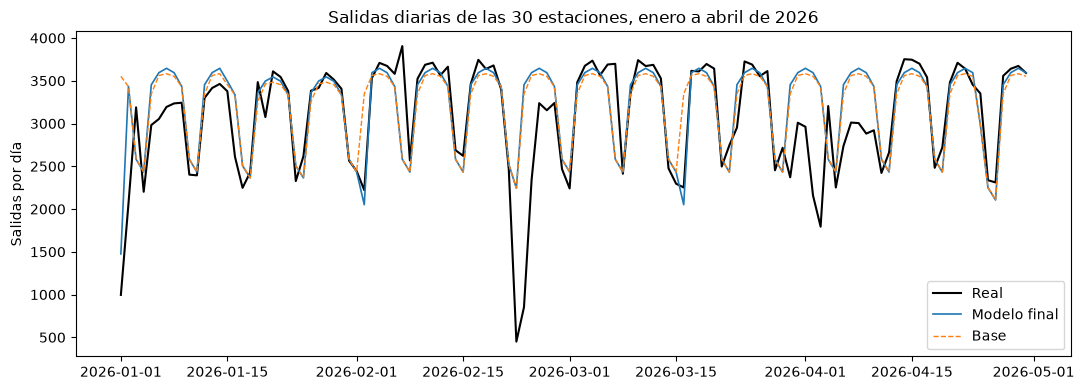

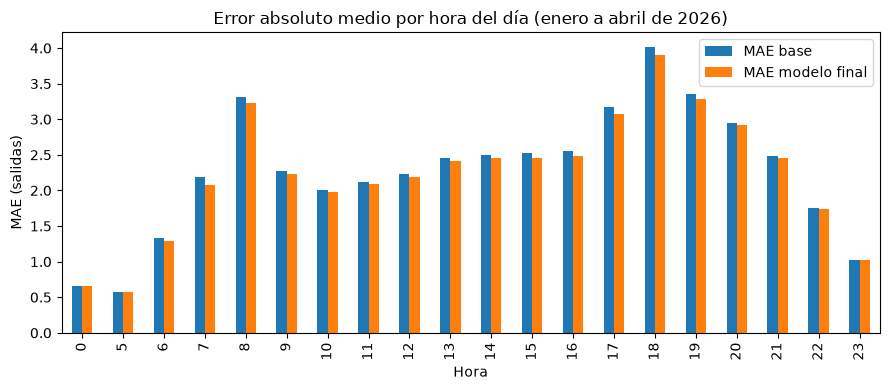

In [15]:
import matplotlib.pyplot as plt
FIGURAS = Path("figuras")

# 1. Salidas diarias reales y predichas (suma de las 30 estaciones)
diario = e.groupby("dia")[["salidas", "pred", "pred_base"]].sum()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diario.index, diario["salidas"], color="black", lw=1.5, label="Real")
ax.plot(diario.index, diario["pred"], lw=1.2, label="Modelo final")
ax.plot(diario.index, diario["pred_base"], lw=1, ls="--", label="Base")
ax.set(title="Salidas diarias de las 30 estaciones, enero a abril de 2026", ylabel="Salidas por día")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "salidas_diarias_2026.png", dpi=150)
plt.show()

# 2. Error por hora del día en 2026
fig, ax = plt.subplots(figsize=(9, 4))
por_hora[["mae_base", "mae_modelo"]].rename(columns={"mae_base": "MAE base", "mae_modelo": "MAE modelo final"}).plot.bar(ax=ax)
ax.set(title="Error absoluto medio por hora del día (enero a abril de 2026)", xlabel="Hora", ylabel="MAE (salidas)")
fig.tight_layout()
fig.savefig(FIGURAS / "error_por_hora_2026.png", dpi=150)
plt.show()

## 13 ¿cuanto recall se gana bajando el umbral de decision?

In [16]:
filas_umbral = []
for factor in (1.0, 0.9, 0.8, 0.7):
    pred_pico = e["pred"] >= factor * e["umbral"]
    filas_umbral.append({
        "Umbral de decisión": f"{factor:.0%} del umbral de pico",
        "Precisión": precision_score(real_pico, pred_pico),
        "Recall": recall_score(real_pico, pred_pico),
        "F1": f1_score(real_pico, pred_pico),
        "Horas marcadas como pico": int(pred_pico.sum()),
    })
umbrales = pd.DataFrame(filas_umbral)
umbrales.to_csv(PROCESADO / "umbral_horas_pico.csv", index=False)
print(umbrales.round(3).to_string(index=False))

     Umbral de decisión  Precisión  Recall    F1  Horas marcadas como pico
100% del umbral de pico      0.540   0.301 0.386                      4131
 90% del umbral de pico      0.511   0.426 0.465                      6196
 80% del umbral de pico      0.448   0.582 0.506                      9631
 70% del umbral de pico      0.363   0.748 0.488                     15314


## 14 los primeros sabados y semana santa tambien se notan en 2024-2025?

In [17]:
d = (tabla.assign(dia=tabla["hora_inicio"].dt.normalize())
     .groupby("dia")["salidas"].sum().to_frame())
d["dow"], d["anio"] = d.index.dayofweek, d.index.year

sabados = d[d["dow"] == 5].copy()
sabados["tipo"] = np.where(sabados.index.day <= 7, "Primer sábado del mes", "Otros sábados")
print("Salidas diarias promedio en sábado (30 estaciones):")
print(sabados.groupby(["anio", "tipo"])["salidas"].agg(["mean", "count"]).round(0).to_string())

print("\nJueves y Viernes Santo contra el promedio de ese día de la semana en el año:")
for fecha in pd.to_datetime(["2024-03-28", "2024-03-29", "2025-04-17", "2025-04-18"]):
    promedio = d[(d["dow"] == fecha.dayofweek) & (d["anio"] == fecha.year)]["salidas"].mean()
    print(f"  {fecha.date()}: {d.loc[fecha, 'salidas']:,.0f} salidas | promedio del año: {promedio:,.0f}")

Salidas diarias promedio en sábado (30 estaciones):
                              mean  count
anio tipo                                
2024 Otros sábados          2605.0     40
     Primer sábado del mes  2655.0     12
2025 Otros sábados          2515.0     40
     Primer sábado del mes  2667.0     12

Jueves y Viernes Santo contra el promedio de ese día de la semana en el año:
  2024-03-28: 2,375 salidas | promedio del año: 3,634
  2024-03-29: 1,904 salidas | promedio del año: 3,457
  2025-04-17: 2,160 salidas | promedio del año: 3,469
  2025-04-18: 1,840 salidas | promedio del año: 3,406
